# Lapse Prediction Model (Simulated Data)
Predicts which donors who gave in 2024 will not give in 2025, using only giving history up to 2024-12-31.

Requires `data/donors.csv` and `data/gifts.csv` from `donor_analysis.ipynb`.

## 1. Setup

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA_DIR = "data"
CHART_DIR = "charts"
SEED = 42
SNAPSHOT = pd.Timestamp("2024-12-31")  # prediction date: only earlier history is used

os.makedirs(CHART_DIR, exist_ok=True)

## 2. Features and Target
Population: donors who gave in 2024. Features use only gifts up to the snapshot date, so no 2025 information leaks into the model. Target: 1 = lapsed (no gift in 2025).

In [2]:
gifts = pd.read_csv(f"{DATA_DIR}/gifts.csv", parse_dates=["gift_date"])
donors = pd.read_csv(f"{DATA_DIR}/donors.csv")

# Features: gifts on or before the snapshot, for donors active in 2024
history = gifts[gifts["gift_date"] <= SNAPSHOT]
active_2024 = history.loc[history["gift_date"].dt.year == 2024, "donor_id"].unique()
history = history[history["donor_id"].isin(active_2024)]

features = history.groupby("donor_id").agg(
    gift_count=("amount", "size"),
    total_given=("amount", "sum"),
    avg_gift=("amount", "mean"),
    first_gift=("gift_date", "min"),
    last_gift=("gift_date", "max"),
)
features["gifts_2024"] = (history[history["gift_date"].dt.year == 2024]
                          .groupby("donor_id").size())
features["months_since_last"] = (SNAPSHOT - features["last_gift"]).dt.days / 30.44
features["is_new_2024"] = (features["first_gift"].dt.year == 2024).astype(int)
features = features.join(donors.set_index("donor_id")["donor_type"])
features["is_corporate"] = (features["donor_type"] == "Corporate").astype(int)

# Target: 1 = lapsed (gave in 2024, no gift in 2025)
gave_2025 = set(gifts.loc[gifts["gift_date"].dt.year == 2025, "donor_id"])
features["lapsed"] = (~features.index.isin(gave_2025)).astype(int)

FEATURE_COLS = ["gift_count", "total_given", "avg_gift", "gifts_2024",
                "months_since_last", "is_new_2024", "is_corporate"]
X = features[FEATURE_COLS]
y = features["lapsed"]

print(f"Donors modeled: {len(X):,}")
print(f"Lapsed: {y.sum():,} ({y.mean():.1%})")


Donors modeled: 2,230
Lapsed: 1,405 (63.0%)


## 3. Train/Test Split
75% train, 25% test, stratified on the target.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
print(f"Train: {len(X_train):,} | Test: {len(X_test):,}")

Train: 1,672 | Test: 558


## 4. Model Training and Evaluation
Logistic regression (interpretable baseline) vs. random forest. Metric: ROC-AUC on the held-out test set.

In [4]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=10,
                                            random_state=SEED),
}

probs = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    probs[name] = model.predict_proba(X_test)[:, 1]
    print(f"{name}: ROC-AUC = {roc_auc_score(y_test, probs[name]):.3f}")

baseline = max(y_test.mean(), 1 - y_test.mean())
print(f"Baseline accuracy (always predict lapsed): {baseline:.1%}")

final_name = "Logistic Regression"
pred = (probs[final_name] >= 0.5).astype(int)
print(f"\n{final_name} (threshold 0.5)")
print(classification_report(y_test, pred, target_names=["returned", "lapsed"]))

Logistic Regression: ROC-AUC = 0.815
Random Forest: ROC-AUC = 0.810
Baseline accuracy (always predict lapsed): 63.1%

Logistic Regression (threshold 0.5)
              precision    recall  f1-score   support

    returned       0.74      0.48      0.58       206
      lapsed       0.75      0.90      0.82       352

    accuracy                           0.75       558
   macro avg       0.74      0.69      0.70       558
weighted avg       0.74      0.75      0.73       558



### 4.1 ROC Curve

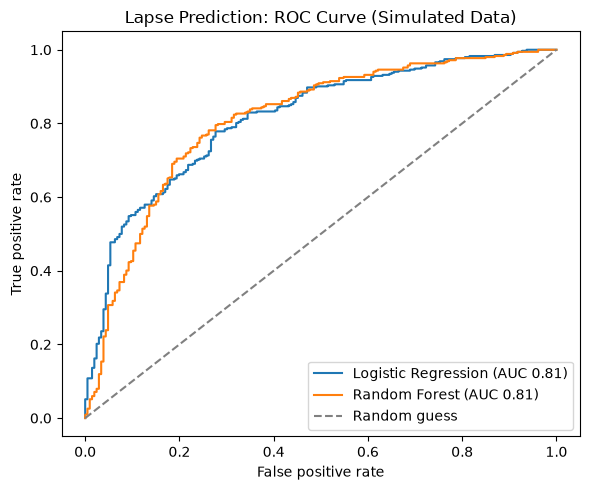

In [5]:
plt.figure(figsize=(6, 5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.2f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
plt.title("Lapse Prediction: ROC Curve (Simulated Data)")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend()
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/lapse_roc_curve.png", dpi=200)
plt.show()

## 5. Lift by Risk Decile
Test donors are ranked by predicted lapse risk and split into 10 equal groups. A useful model shows a high actual lapse rate in decile 1 and a low one in decile 10.

             donors  actual_lapse_rate
risk_decile                           
1                56              0.929
2                56              0.929
3                56              0.946
4                55              0.764
5                56              0.643
6                56              0.696
7                55              0.473
8                56              0.411
9                56              0.357
10               56              0.161


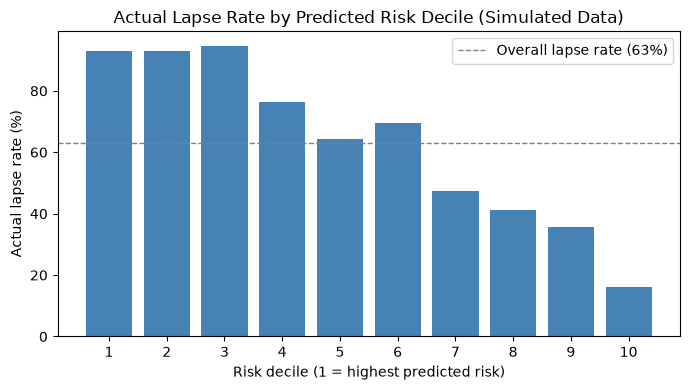

In [6]:
scored = pd.DataFrame({"actual_lapsed": y_test.values, "risk": probs[final_name]})
scored["risk_decile"] = pd.qcut(scored["risk"].rank(method="first", ascending=False),
                                10, labels=range(1, 11))
decile = scored.groupby("risk_decile", observed=True)["actual_lapsed"].agg(["count", "mean"])
decile.columns = ["donors", "actual_lapse_rate"]
print(decile.round(3))

plt.figure(figsize=(7, 4))
plt.bar(decile.index.astype(str), decile["actual_lapse_rate"] * 100, color="steelblue")
plt.axhline(y_test.mean() * 100, color="gray", linestyle="--", linewidth=1,
            label=f"Overall lapse rate ({y_test.mean():.0%})")
plt.title("Actual Lapse Rate by Predicted Risk Decile (Simulated Data)")
plt.xlabel("Risk decile (1 = highest predicted risk)")
plt.ylabel("Actual lapse rate (%)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/lapse_rate_by_risk_decile.png", dpi=200)
plt.show()

## 6. Feature Importance
Random forest importance of each feature.

total_given          0.359
avg_gift             0.248
gift_count           0.142
months_since_last    0.115
gifts_2024           0.090
is_new_2024          0.027
is_corporate         0.020
dtype: float64


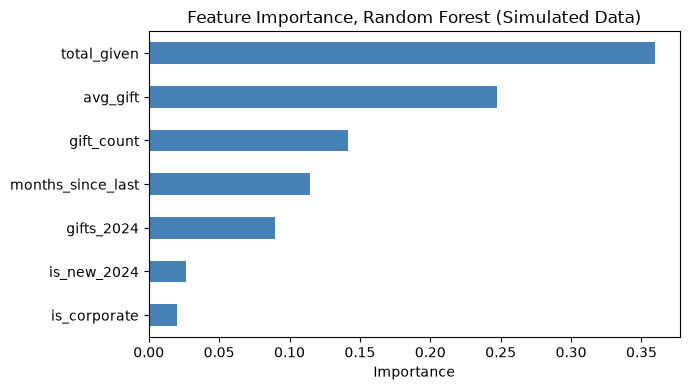

In [7]:
importance = pd.Series(models["Random Forest"].feature_importances_,
                       index=FEATURE_COLS).sort_values(ascending=False)
print(importance.round(3))

plt.figure(figsize=(7, 4))
importance.sort_values().plot(kind="barh", color="steelblue")
plt.title("Feature Importance, Random Forest (Simulated Data)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/lapse_feature_importance.png", dpi=200)
plt.show()

## 7. Notes
- Backtest: the 2025 outcome is already known and is used only as the target and for evaluation. In production, the model would score current donors whose outcome is unknown.
- Features use only gifts up to 2024-12-31 to avoid data leakage.
- Data is simulated, so the model recovers patterns built into the simulation (gift size and frequency separate the hidden donor segments).